# RQ1: Translation performance

Rebuilds Table II and Fig. 2 of the paper from the released result files in `results/` (tier A: no model, no GPU).
Strict F1 counts an SLO as correct only if type, metric, comparator, qualifier, value and unit all match a ground-truth SLO.
In the code the setups are called `zs3`, `fs3`, `zs3_cot`, `fs3_cot`; the paper (and this table) writes `zs`, `fs`, `zs-cot`, `fs-cot`.

In [1]:
import pandas as pd
from pathlib import Path
from IPython.display import Image, display
RES = Path("results")
t = pd.read_csv(RES / "tab2_rq1.csv")
t

,family,model,zs F1,zs EM,fs F1,fs EM,zs-cot F1,zs-cot EM,fs-cot F1,fs-cot EM,mean F1
0,Qwen3.5,Qwen3.5-4B,0.918,0.820,0.910,0.774,0.892,0.772,0.929,0.845,0.912
1,Qwen3.5,Qwen3.5-9B,0.921,0.835,0.922,0.802,0.942,0.879,0.930,0.823,0.929
2,Gemma 4,Gemma-4-E2B,0.591,0.397,0.602,0.399,0.850,0.695,0.886,0.747,0.732
3,Gemma 4,Gemma-4-E4B,0.726,0.403,0.872,0.733,0.883,0.754,0.943,0.879,0.856
4,Ministral 3,Ministral-3-3B,0.408,0.159,0.714,0.493,0.479,0.236,0.847,0.702,0.612
5,Ministral 3,Ministral-3-8B,0.889,0.779,0.917,0.795,0.896,0.779,0.920,0.825,0.905
6,Granite 4.1,Granite-4.1-3B,0.248,0.188,0.651,0.359,0.269,0.150,0.522,0.253,0.423
7,Granite 4.1,Granite-4.1-8B,0.764,0.587,0.855,0.672,0.776,0.601,0.867,0.716,0.816
8,Llama 3,Llama-3.2-3B,0.114,0.035,0.440,0.167,0.101,0.006,0.470,0.140,0.281
9,Llama 3,Llama-3.1-8B,0.448,0.286,0.749,0.507,0.433,0.200,0.756,0.501,0.597


## Table II (as printed in the paper)
Columns: strict micro-F1 and exact match (EM) for each setup, and the mean F1 over the four setups.

In [2]:
display(t.set_index(["family", "model"]).round(3))

zs F1  zs EM  fs F1  fs EM  zs-cot F1  zs-cot EM  \
family      model                                                              
Qwen3.5     Qwen3.5-4B      0.918  0.820  0.910  0.774      0.892      0.772   
            Qwen3.5-9B      0.921  0.835  0.922  0.802      0.942      0.879   
Gemma 4     Gemma-4-E2B     0.591  0.397  0.602  0.399      0.850      0.695   
            Gemma-4-E4B     0.726  0.403  0.872  0.733      0.883      0.754   
Ministral 3 Ministral-3-3B  0.408  0.159  0.714  0.493      0.479      0.236   
            Ministral-3-8B  0.889  0.779  0.917  0.795      0.896      0.779   
Granite 4.1 Granite-4.1-3B  0.248  0.188  0.651  0.359      0.269      0.150   
            Granite-4.1-8B  0.764  0.587  0.855  0.672      0.776      0.601   
Llama 3     Llama-3.2-3B    0.114  0.035  0.440  0.167      0.101      0.006   
            Llama-3.1-8B    0.448  0.286  0.749  0.507      0.433      0.200   

                            fs-cot F1  fs-cot EM  mean F1  
family      model                                          
Qwen3.5     Qwen3.5-4B          0.929      0.845    0.912  
            Qwen3.5-9B          0.930      0.823    0.929  
Gemma 4     Gemma-4-E2B         0.886      0.747    0.732  
            Gemma-4-E4B         0.943      0.879    0.856  
Ministral 3 Ministral-3-3B      0.847      0.702    0.612  
            Ministral-3-8B      0.920      0.825    0.905  
Granite 4.1 Granite-4.1-3B      0.522      0.253    0.423  
            Granite-4.1-8B      0.867      0.716    0.816  
Llama 3     Llama-3.2-3B        0.470      0.140    0.281  
            Llama-3.1-8B        0.756      0.501    0.597

## Checks against the sentences of Section IV-A
Each line recomputes a number from the released CSVs. A failed assertion would mean the text and the data disagree.

In [3]:
f1 = t.melt(id_vars=["model"], value_vars=["zs F1", "fs F1", "zs-cot F1", "fs-cot F1"], var_name="setup", value_name="F1")
em = t.melt(id_vars=["model"], value_vars=["zs EM", "fs EM", "zs-cot EM", "fs-cot EM"], var_name="setup", value_name="EM")
lo, hi = f1.loc[f1.F1.idxmin()], f1.loc[f1.F1.idxmax()]
print("F1 range:", lo.F1, lo.model, lo.setup, "to", hi.F1, hi.model, hi.setup)
assert (lo.F1, lo.model) == (0.101, "Llama-3.2-3B") and (hi.F1, hi.model) == (0.943, "Gemma-4-E4B")
print("best exact match:", em.EM.max(), list(em[em.EM == em.EM.max()].model))
assert em.EM.max() == 0.879
print("configurations with F1 >= 0.941:", [(r.model, r.setup, r.F1) for r in f1[f1.F1 >= 0.941].itertuples()])
assert len(f1[f1.F1 >= 0.941]) == 2
rank = t.set_index("model")["mean F1"].sort_values(ascending=False)
print(rank.head(3).to_dict())
assert rank.index[0] == "Qwen3.5-9B" and rank.index[1] == "Qwen3.5-4B"
eight_b = ["Ministral-3-8B", "Granite-4.1-8B", "Llama-3.1-8B", "Gemma-4-E4B"]
assert rank["Qwen3.5-4B"] > rank[eight_b].max()
best = sum(r["fs-cot F1"] == max(r[c] for c in ["zs F1", "fs F1", "zs-cot F1", "fs-cot F1"]) for _, r in t.iterrows())
print("fs-cot is the best setup for", best, "of 10 models")
assert best == 8
print("Ministral-3-3B", t.set_index("model").loc["Ministral-3-3B", ["zs F1", "fs-cot F1"]].tolist(),
      "| Gemma-4-E2B", t.set_index("model").loc["Gemma-4-E2B", ["zs F1", "fs-cot F1"]].tolist())

F1 range: 0.101 Llama-3.2-3B zs-cot F1 to 0.943 Gemma-4-E4B fs-cot F1
best exact match: 0.879 ['Qwen3.5-9B', 'Gemma-4-E4B']
configurations with F1 >= 0.941: [('Qwen3.5-9B', 'zs-cot F1', 0.942), ('Gemma-4-E4B', 'fs-cot F1', 0.943)]
{'Qwen3.5-9B': 0.929, 'Qwen3.5-4B': 0.912, 'Ministral-3-8B': 0.905}
fs-cot is the best setup for 8 of 10 models
Ministral-3-3B [0.408, 0.847] | Gemma-4-E2B [0.591, 0.886]


In [4]:
gain = pd.read_csv(RES / "V-06_large_minus_small.csv", index_col=0)["mean over prompts"].round(3)
print(gain.to_dict())
assert gain["Qwen"] == 0.016 and gain["Granite"] == 0.393

{'Qwen': 0.016, 'Gemma': 0.124, 'Ministral': 0.293, 'Granite': 0.393, 'Llama': 0.316}


## Fig. 2: explicit vs implicit SLOs (fs-cot, Qwen3.5 and Gemma 4)
The underlying numbers are in `results/V-08_f1_explicit_implicit.csv`; the figure is drawn by `make_table_and_figure.py`.

     model  explicit  implicit
Qwen3.5-4B     0.985     0.688
Qwen3.5-9B     0.985     0.692
Gemma4-E2B     0.919     0.739
Gemma4-E4B     0.997     0.714


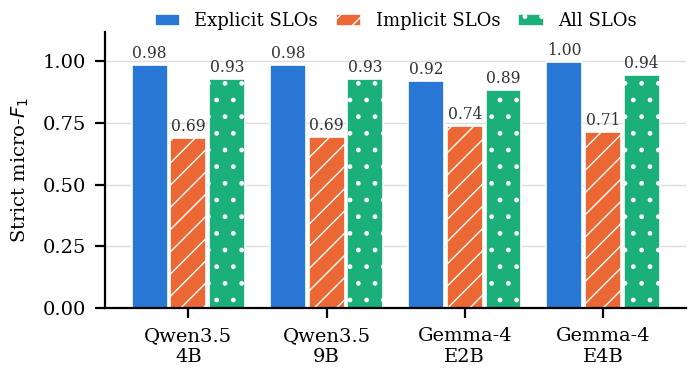

In [5]:
ex = pd.read_csv(RES / "V-08_f1_explicit_implicit.csv")
x = ex[(ex.prompt == "fs3 CoT") & ex.model.isin(["Qwen3.5-4B", "Qwen3.5-9B", "Gemma4-E2B", "Gemma4-E4B"])]
print(x[["model", "explicit", "implicit"]].round(3).to_string(index=False))
assert x.explicit.round(3).min() == 0.919 and x.explicit.round(3).max() == 0.997
assert x.implicit.round(3).min() == 0.688 and x.implicit.round(3).max() == 0.739
display(Image("figures/fig2_explicit_grounded.png", width=480))